In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

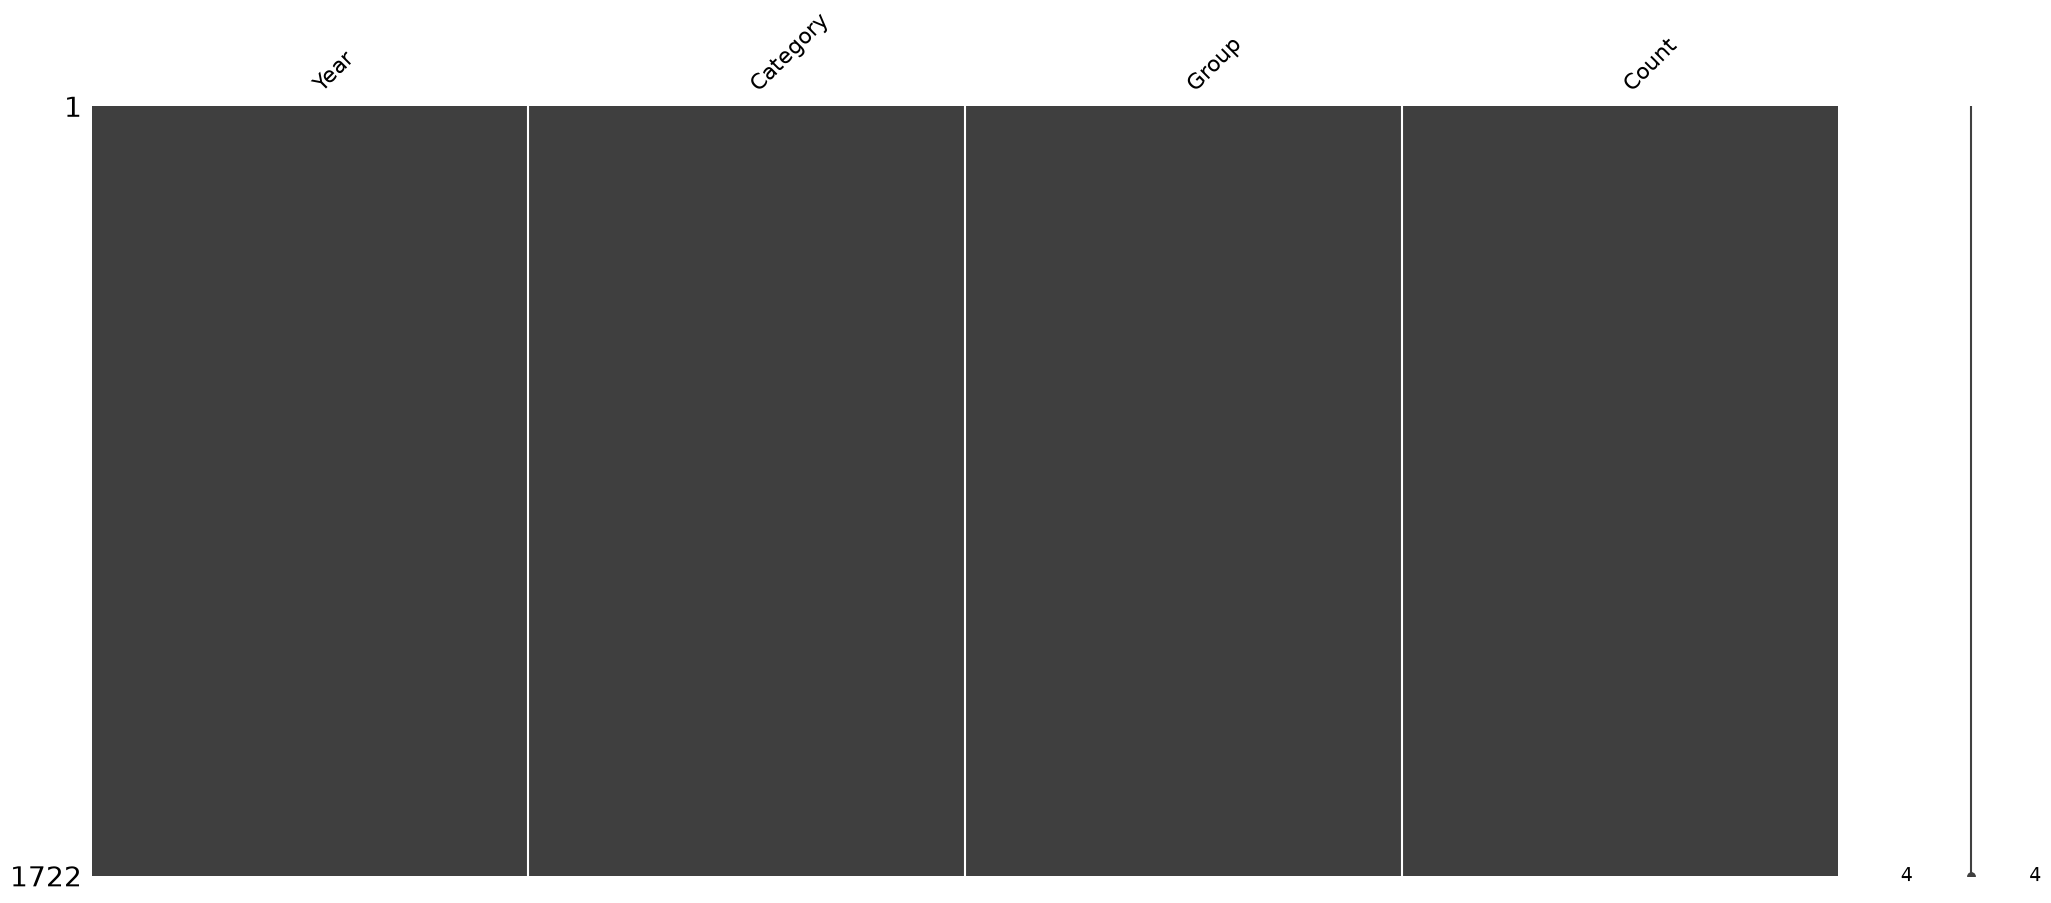

In [3]:
persons_living_with_hiv_aids = pd.read_csv("persons-living-with-hiv-aids.csv")
msno.matrix(persons_living_with_hiv_aids)
plt.show()

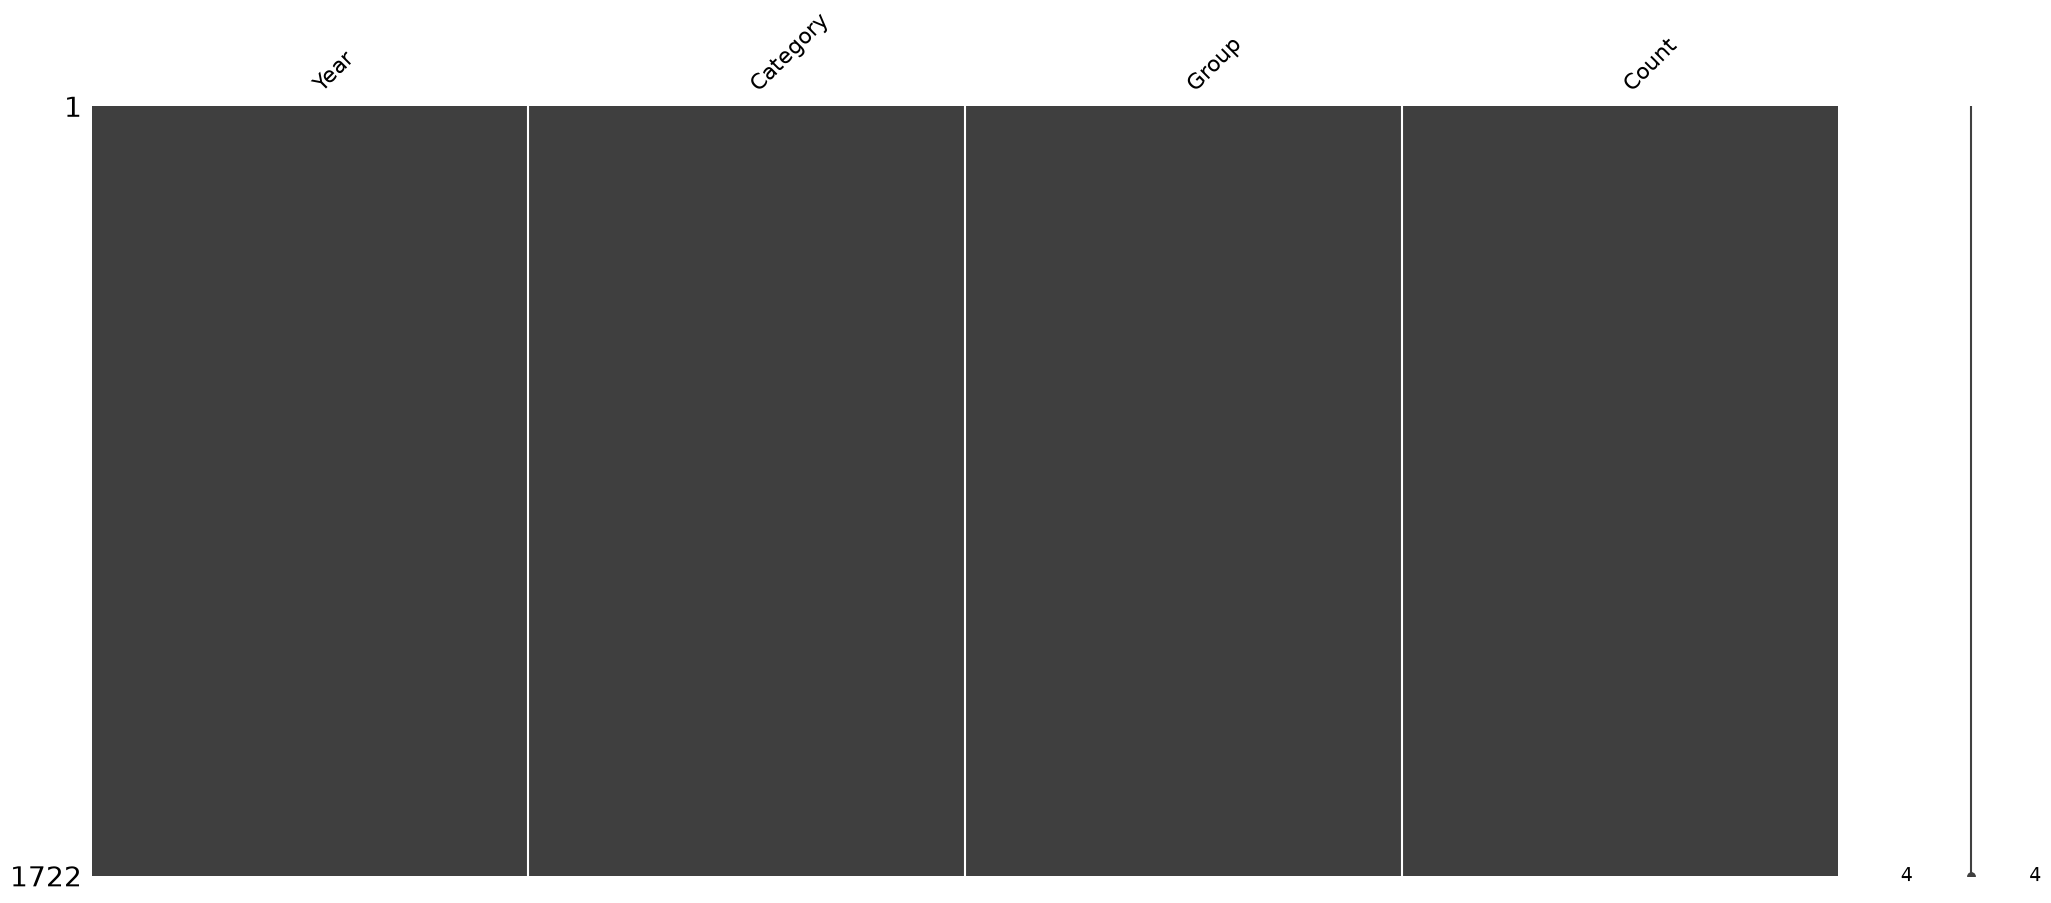

In [4]:
persons_newly_diagnosed_with_hiv = pd.read_csv("persons-newly-diagnosed-with-hiv.csv")
msno.matrix(persons_newly_diagnosed_with_hiv)
plt.show()

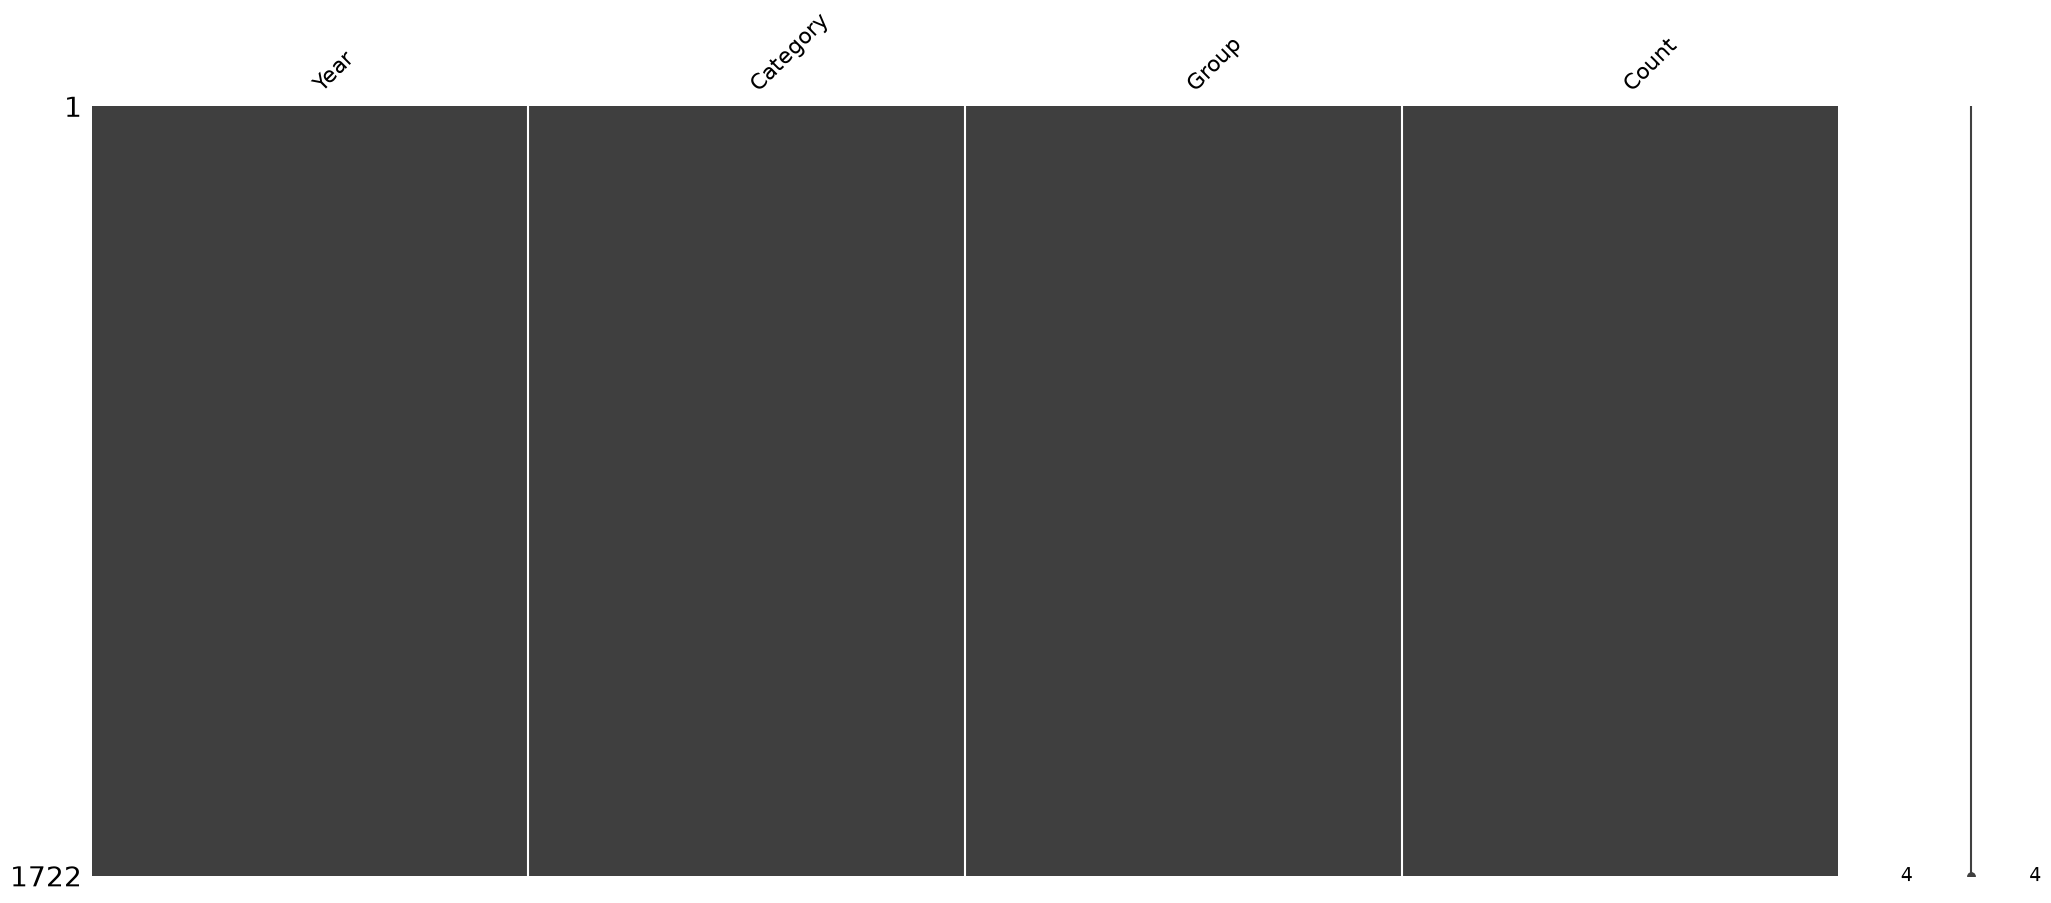

In [5]:
deaths_of_persons_diagnosed_with_hiv_aids = pd.read_csv("deaths-of-persons-diagnosed-with-hiv-aids.csv")
msno.matrix(deaths_of_persons_diagnosed_with_hiv_aids)
plt.show()

In [6]:
df1 = persons_living_with_hiv_aids.rename(columns={'Count': 'Count_Living'})
df2 = persons_newly_diagnosed_with_hiv.rename(columns={'Count': 'Count_New'})
df3 = deaths_of_persons_diagnosed_with_hiv_aids.rename(columns={'Count': 'Count_Deaths'})

combined = (
    df1
    .merge(df2, on=['Year', 'Category', 'Group'])
    .merge(df3, on=['Year', 'Category', 'Group'])
)

combined.head(10)

combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 658 entries, 0 to 657
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Year          658 non-null    int64
 1   Category      658 non-null    str  
 2   Group         658 non-null    str  
 3   Count_Living  658 non-null    int64
 4   Count_New     658 non-null    int64
 5   Count_Deaths  658 non-null    int64
dtypes: int64(4), str(2)
memory usage: 31.0 KB


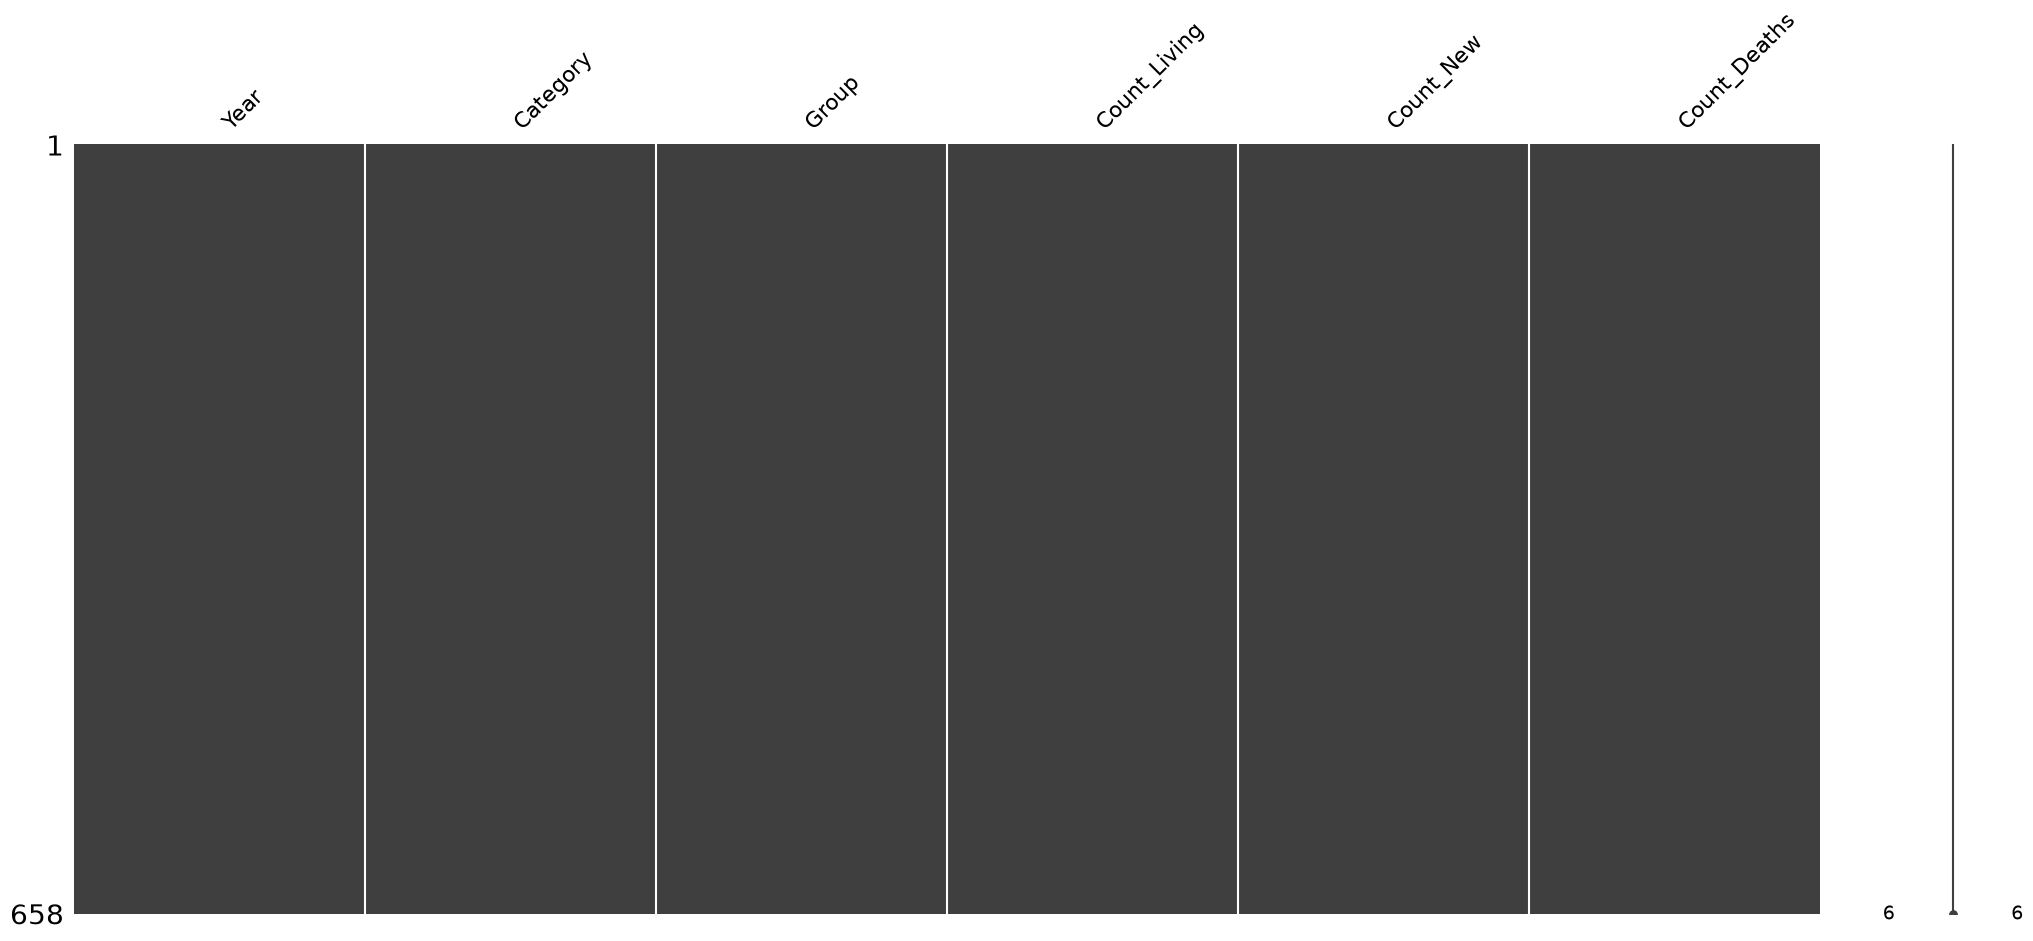

In [7]:
msno.matrix(combined)
plt.show()

In [8]:
measure_cols = ['Count_Living', 'Count_New', "Count_Deaths"]
grp_by = combined.groupby(['Year', 'Category'])[measure_cols].mean()

print(grp_by)

                                                         Count_Living  \
Year Category                                                           
2010 Current Gender                                      23123.400000   
     Race/Ethnicity                                      14452.125000   
     Sex at Birth                                        57808.500000   
     Transmission Category: Alternative Gender Adult...      0.600000   
     Transmission Category: Child (<12 Years Old at ...     58.000000   
...                                                               ...   
2023 Transmission Category: Child (<12 Years Old at ...     21.000000   
     Transmission Category: Cisgender Men Adult or A...  15376.250000   
     Transmission Category: Cisgender Women Adult or...   2843.166667   
     Transmission Category: Trans Men Adult or Adole...     22.400000   
     Transmission Category: Trans Women Adult or Ado...    590.400000   

                                                  

In [ ]:
# Combine the CSVs without error
# Solution provided by Prof. Alvarado

'''It turns out that each table had two different category names, corresponding to their unit of observation.
So, [Prof. Alvarado] just changed them, but the user should know what 'Age' and 'City' actually mean when viewing results.'''

key = ['Year', 'Category', 'Group']

df1 = persons_living_with_hiv_aids.rename(columns={'Count': 'Count_Living'})
df1['Category'] = df1['Category'].replace({'Age at Year End (in years)':'Age', 'City of Current Residence':'City'})
df1 = df1.set_index(key)

df2 = persons_newly_diagnosed_with_hiv.rename(columns={'Count': 'Count_New'})
df2['Category'] = df2['Category'].replace({'Age at Diagnosis (in years)':'Age', 'City of Residence at Diagnosis':'City'})
df2 = df2.set_index(key)

df3 = deaths_of_persons_diagnosed_with_hiv_aids.rename(columns={'Count': 'Count_Deaths'})
df3['Category'] = df3['Category'].replace({'Age at Death (in years)':'Age', 'City of Residence at Death':'City'})
df3 = df3.set_index(key)

official_combined = df1.join(df2).join(df3)

official_combined.head()

Count_Living  Count_New  Count_Deaths
Year Category Group                                          
2010 Age      0 to 11            174       16.0           1.0
              12 to 14           112        3.0           0.0
              15 to 17           206       30.0           1.0
              18 to 19           345      131.0           1.0
              20 to 24          3001      780.0          15.0

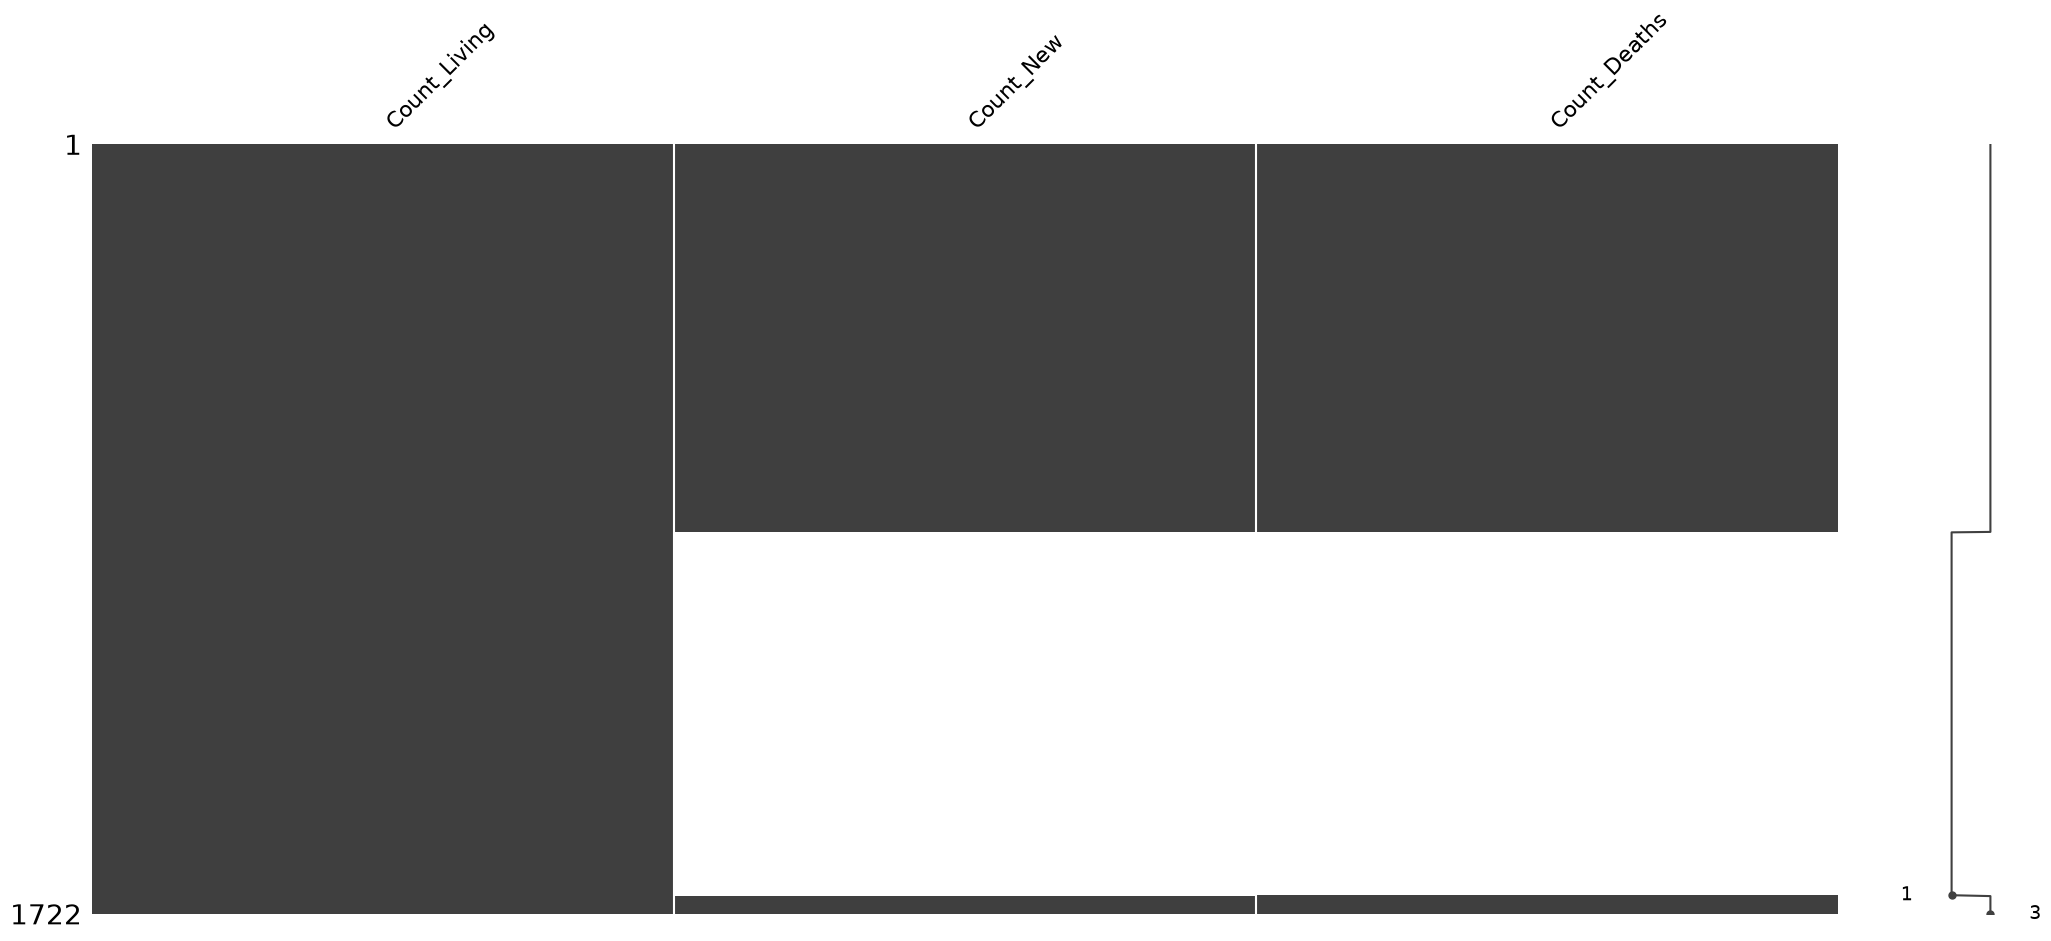

In [11]:
msno.matrix(official_combined)
plt.show()

In [ ]:
# Showing that the age counts actually show up (they were ommitted in the initial merge)

age_official_combined = official_combined.query("Category == 'Age'")

age_official_combined.head()

Count_Living  Count_New  Count_Deaths
Year Category Group                                          
2010 Age      0 to 11            174       16.0           1.0
              12 to 14           112        3.0           0.0
              15 to 17           206       30.0           1.0
              18 to 19           345      131.0           1.0
              20 to 24          3001      780.0          15.0

In [15]:
# Showing that the city counts actually show up (they were ommitted in the initial merge)

city_official_combined = official_combined.query("Category == 'City'")

city_official_combined.head()

Count_Living  Count_New  Count_Deaths
Year Category Group                                            
2010 City     Berkeley             405        NaN           9.0
              Long Beach          4482      147.0          55.0
              Pasadena             543       19.0          11.0
2011 City     Berkeley             418       12.0           3.0
              Long Beach          4484      160.0          74.0